# Import Libs

In [82]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

IVORY = "#F6F1EA"
OXBLOOD = "#6B1F2A"
STONE = "#CFC6BA"
INK = "#2F2A27"

plt.rcParams.update({
    "figure.facecolor": IVORY,
    "axes.facecolor": IVORY,
    "axes.edgecolor": INK,
    "axes.labelcolor": INK,
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
    "text.color": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "grid.color": STONE,
    "grid.alpha": 0.35,
    "axes.axisbelow": True,
})

# Load Data

In [83]:
DATA_DIR = Path("../gis-analytics-assessment-materials")
with (DATA_DIR / "products.json").open(encoding="utf-8") as f:
    products = pd.DataFrame(json.load(f))

analytics_columns = [
    "month",
    "channel",
    "device",
    "sessions",
    "product_views",
    "add_to_carts",
    "checkouts_started",
    "orders",
    "revenue_gbp",
    "ad_spend_gbp",
]

analytics = pd.read_csv(
    DATA_DIR / "analytics.csv",
    header=None,
    skiprows=1,
    names=analytics_columns,
)

# Device Funnel

,sessions,product_views,add_to_carts,checkouts_started,orders,view_to_cart,cart_to_checkout,checkout_to_order
device,,,,,,,,
desktop,6570,12639,370,227,130,2.9%,61.4%,57.3%
mobile,25097,53571,1409,755,109,2.6%,53.6%,14.4%


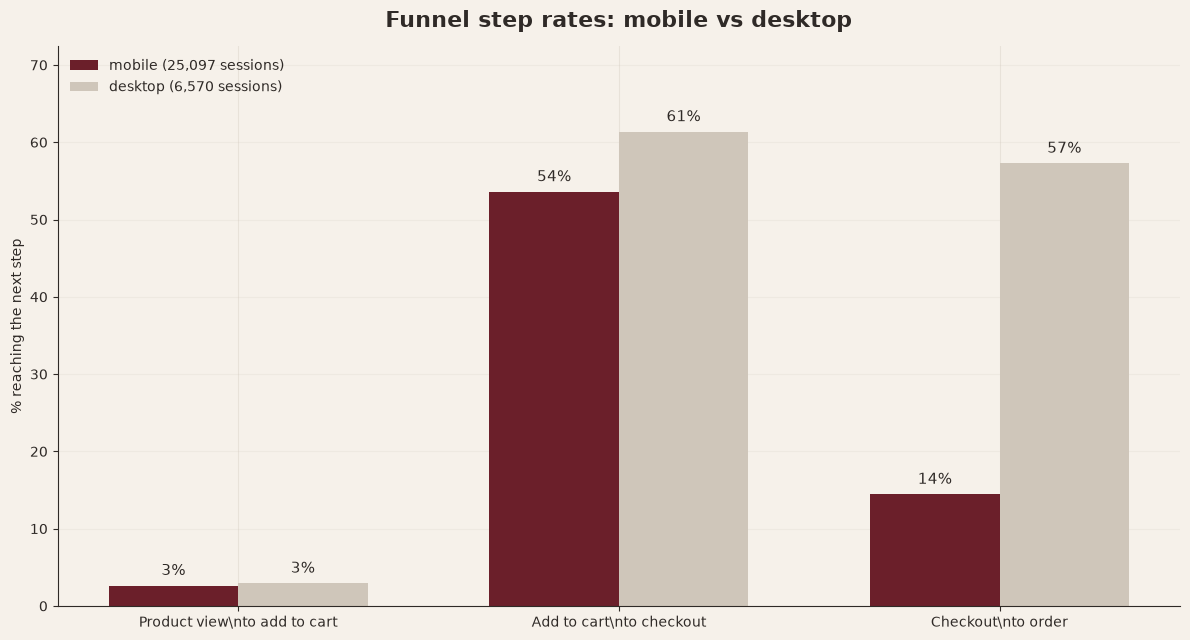

In [84]:
# Aggregate metrics by device and calculate true stage-to-stage conversion rates.
# Each rate uses the number of users/events at the previous funnel step as its denominator.
device = analytics.groupby("device", as_index=True).agg(
    sessions=("sessions", "sum"),
    product_views=("product_views", "sum"),
    add_to_carts=("add_to_carts", "sum"),
    checkouts_started=("checkouts_started", "sum"),
    orders=("orders", "sum"),
    revenue_gbp=("revenue_gbp", "sum"),
)

device["view_to_cart"] = device["add_to_carts"] / device["product_views"].replace(0, float("nan"))
device["cart_to_checkout"] = device["checkouts_started"] / device["add_to_carts"].replace(0, float("nan"))
device["checkout_to_order"] = device["orders"] / device["checkouts_started"].replace(0, float("nan"))

display(device[[
    "sessions", "product_views", "add_to_carts", "checkouts_started", "orders",
    "view_to_cart", "cart_to_checkout", "checkout_to_order"
]].style.format({
    "view_to_cart": "{:.1%}",
    "cart_to_checkout": "{:.1%}",
    "checkout_to_order": "{:.1%}",
}))

stages = [
    ("view_to_cart", "Product view\\nto add to cart"),
    ("cart_to_checkout", "Add to cart\\nto checkout"),
    ("checkout_to_order", "Checkout\\nto order"),
]

# Match the requested visual style: grouped bars, clear percentage labels, brand palette.
fig, ax = plt.subplots(figsize=(12, 6.5))
x = list(range(len(stages)))
width = 0.34
colours = {"mobile": OXBLOOD, "desktop": STONE}
device_order = ["mobile", "desktop"]

for i, device_name in enumerate(device_order):
    if device_name not in device.index:
        continue
    values = [device.loc[device_name, col] * 100 for col, _ in stages]
    offset = (i - 0.5) * width
    bars = ax.bar(
        [j + offset for j in x], values, width,
        color=colours[device_name],
        label=f"{device_name} ({device.loc[device_name, 'sessions']:,.0f} sessions)"
    )
    for bar, value in zip(bars, values):
        if pd.notna(value):
            ax.annotate(
                f"{value:.0f}%",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 5), textcoords="offset points",
                ha="center", va="bottom", fontsize=11
            )

ax.set_xticks(x, [label for _, label in stages])
ax.set_ylabel("% reaching the next step")
ax.set_title("Funnel step rates: mobile vs desktop", fontsize=16, fontweight="bold", pad=14)
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, max(
    device.loc[d, col] * 100
    for d in device_order if d in device.index
    for col, _ in stages
) * 1.18)
plt.tight_layout()
plt.show()


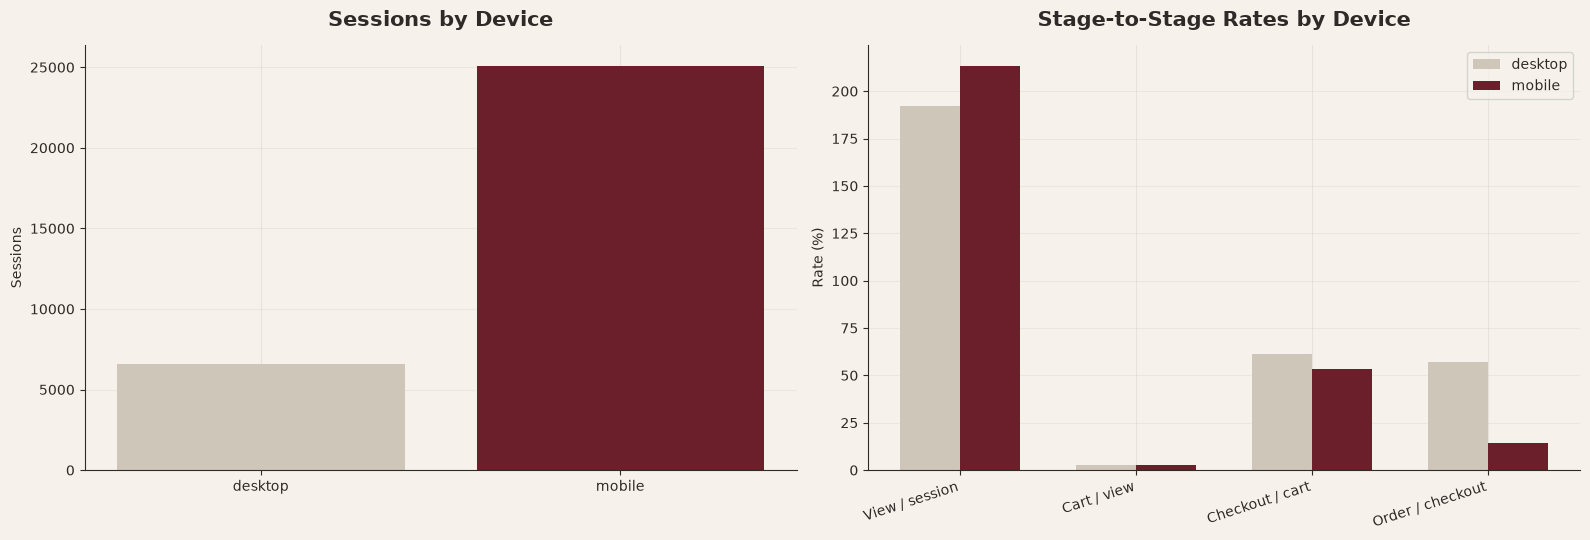

,sessions,product_views,add_to_carts,checkouts_started,orders,View / session,Cart / view,Checkout / cart,Order / checkout
device,,,,,,,,,
desktop,6570,12639,370,227,130,192.4%,2.9%,61.4%,57.3%
mobile,25097,53571,1409,755,109,213.5%,2.6%,53.6%,14.4%


In [85]:
# Device-level overview: sessions and stage-to-stage funnel rates
# Aggregate across all months and acquisition channels before calculating rates.
device_metrics = (
    analytics.groupby("device", as_index=True)[
        ["sessions", "product_views", "add_to_carts", "checkouts_started", "orders"]
    ]
    .sum()
)

# Ratios are event counts at each stage divided by the preceding stage.
# Product views per session can exceed 100% because one session may include multiple views.
device_rates = pd.DataFrame(index=device_metrics.index)
device_rates["View / session"] = (
    device_metrics["product_views"] / device_metrics["sessions"].replace(0, float("nan")) * 100
)
device_rates["Cart / view"] = (
    device_metrics["add_to_carts"] / device_metrics["product_views"].replace(0, float("nan")) * 100
)
device_rates["Checkout / cart"] = (
    device_metrics["checkouts_started"] / device_metrics["add_to_carts"].replace(0, float("nan")) * 100
)
device_rates["Order / checkout"] = (
    device_metrics["orders"] / device_metrics["checkouts_started"].replace(0, float("nan")) * 100
)

# Two-panel layout matching the reference image.
fig, (ax_sessions, ax_rates) = plt.subplots(1, 2, figsize=(16, 5.5))
device_order = [d for d in ["desktop", "mobile"] if d in device_metrics.index]
brand_colours = {"desktop": STONE, "mobile": OXBLOOD}

# Left: total sessions by device
session_values = [device_metrics.loc[d, "sessions"] for d in device_order]
ax_sessions.bar(
    device_order,
    session_values,
    color=[brand_colours[d] for d in device_order],
)
ax_sessions.set_title("Sessions by Device", fontsize=15)
ax_sessions.set_ylabel("Sessions")
ax_sessions.grid(axis="y", alpha=0.25)
ax_sessions.set_axisbelow(True)
ax_sessions.spines[["top", "right"]].set_visible(False)

# Right: four rates, with desktop and mobile bars side by side
stage_labels = ["View / session", "Cart / view", "Checkout / cart", "Order / checkout"]
x = list(range(len(stage_labels)))
width = 0.34

for i, device_name in enumerate(device_order):
    vals = device_rates.loc[device_name, stage_labels].tolist()
    offset = (i - (len(device_order) - 1) / 2) * width
    ax_rates.bar(
        [position + offset for position in x],
        vals,
        width=width,
        label=device_name,
        color=brand_colours[device_name],
    )

ax_rates.set_title("Stage-to-Stage Rates by Device", fontsize=15)
ax_rates.set_ylabel("Rate (%)")
ax_rates.set_xticks(x, stage_labels, rotation=18, ha="right")
ax_rates.legend(title=None)
ax_rates.grid(axis="y", alpha=0.25)
ax_rates.set_axisbelow(True)
ax_rates.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

display(device_metrics.join(device_rates).style.format({
    "View / session": "{:.1f}%",
    "Cart / view": "{:.1f}%",
    "Checkout / cart": "{:.1f}%",
    "Order / checkout": "{:.1f}%",
}))


# Orders By product category

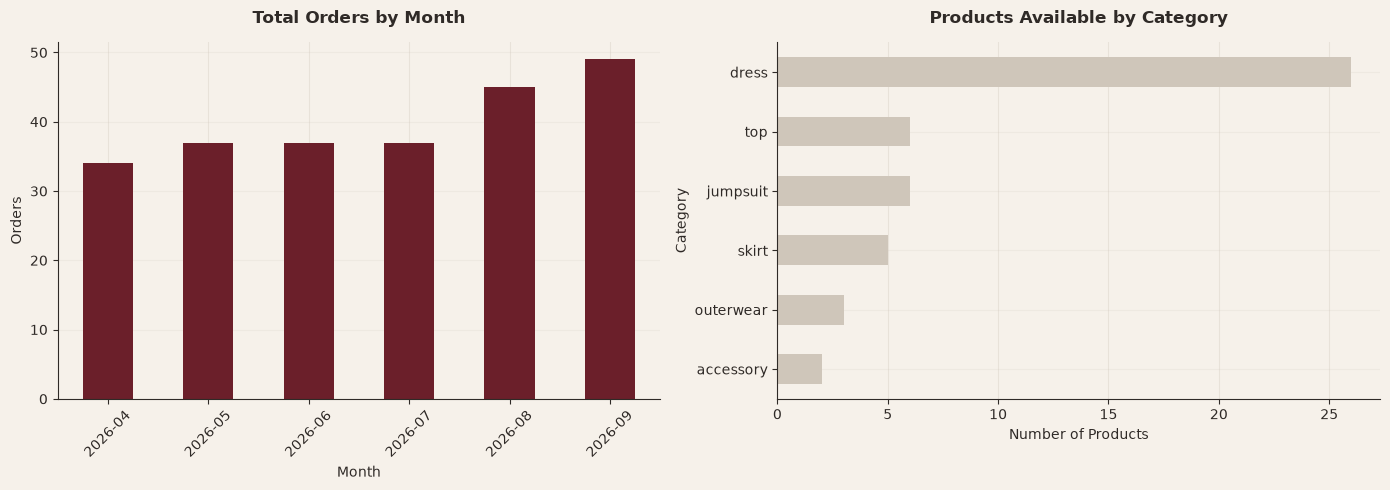

In [86]:
# Aggregate monthly orders
monthly_orders = analytics.groupby("month")["orders"].sum()

# Count products in each category
category_counts = products["category"].value_counts().sort_values()

# Create two-panel diagram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

monthly_orders.plot(
    kind="bar", ax=axes[0], color=OXBLOOD, title="Total Orders by Month"
)
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Orders")
axes[0].tick_params(axis="x", rotation=45)

category_counts.plot(
    kind="barh", ax=axes[1], color=STONE, title="Products Available by Category"
)
axes[1].set_xlabel("Number of Products")
axes[1].set_ylabel("Category")
for axis in axes:
    axis.grid(axis="y", alpha=0.18)
    axis.set_axisbelow(True)
    axis.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

# Channels: share of sessions vs share of revenue
Ask: which channels bring visitors, and which bring money?

sessions  orders  revenue  session_share_%   cvr
channel        device                                                   
direct         desktop      1898      46    15445             5.99  2.42
               mobile       3099      26     8962             9.79  0.84
email          desktop       786      39    13026             2.48  4.96
               mobile        958      13     4072             3.03  1.36
instagram      desktop      2607      31    10397             8.23  1.19
               mobile      16027      56    18954            50.61  0.35
organic_search desktop       531       6     2047             1.68  1.13
               mobile        735       6     2103             2.32  0.82
paid_social    desktop       418       2      668             1.32  0.48
               mobile       3780       8     2708            11.94  0.21
referral       desktop       330       6     2058             1.04  1.82
               mobile        498       0        0             1.57  0.00

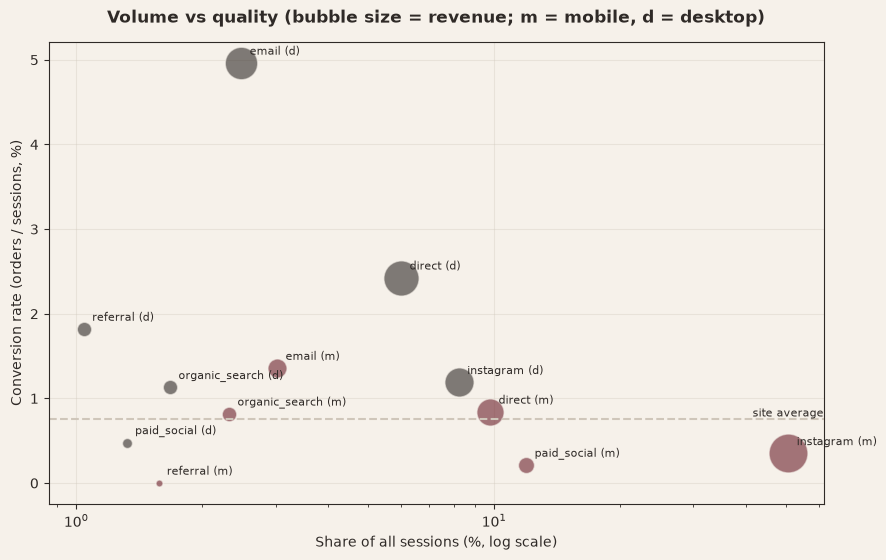

In [87]:
cells_tbl = (
    analytics.groupby(["channel", "device"])
    .agg(
        sessions=("sessions", "sum"),
        orders=("orders", "sum"),
        revenue=("revenue_gbp", "sum"),
    )
)
cells_tbl["cvr"] = cells_tbl["orders"] / cells_tbl["sessions"].replace(0, float("nan"))
tot = pd.Series({"cvr": analytics["orders"].sum() / analytics["sessions"].sum()})

cd = cells_tbl.copy()
cd["session_share_%"] = cd.sessions / cd.sessions.sum() * 100
display(cd[["sessions", "orders", "revenue", "session_share_%", "cvr"]].assign(cvr=lambda t: t.cvr * 100).round(2))

fig, ax = plt.subplots(figsize=(10, 6))
for (c, d), r in cd.iterrows():
    colour = OXBLOOD if d == "mobile" else INK
    ax.scatter(r["session_share_%"], r.cvr * 100, s=max(r.revenue, 0) / 25 + 25,
               color=colour, alpha=0.6, edgecolor=IVORY)
    ax.annotate(f"{c} ({d[0]})", (r["session_share_%"], r.cvr * 100),
                xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Share of all sessions (%, log scale)")
ax.set_ylabel("Conversion rate (orders / sessions, %)")
ax.set_title("Volume vs quality (bubble size = revenue; m = mobile, d = desktop)")
ax.axhline(tot.cvr * 100, color=STONE, ls="--")
ax.text(ax.get_xlim()[1], tot.cvr * 100, " site average", va="bottom", ha="right", fontsize=8)
plt.show()

# Paid social economics
Ask: did the August-September test pay for itself after margin?

,sessions,orders,revenue_gbp,ad_spend_gbp,gross_profit,net,revenue_per_gbp,cost_per_order
month,,,,,,,,
2026-08,1899,4,1304,1200,717.2,-482.8,1.09,300.0
2026-09,2299,6,2072,1500,1139.6,-360.4,1.38,250.0
Total,4198,10,3376,2700,1856.8,-843.2,1.25,270.0


Break-even needs £1.82 revenue per £1 spent at a 55% margin. Actual: £1.25.


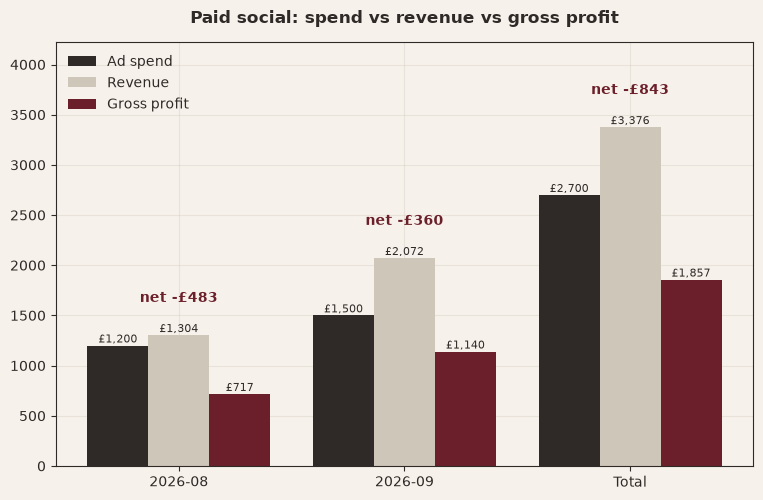

In [88]:
import numpy as np

ps = analytics[analytics.channel == "paid_social"].groupby("month")[["sessions", "orders", "revenue_gbp", "ad_spend_gbp"]].sum()
ps = ps[ps.ad_spend_gbp > 0]
ps.loc["Total"] = ps.sum()
ps["gross_profit"] = ps.revenue_gbp * MARGIN
ps["net"] = ps.gross_profit - ps.ad_spend_gbp
ps["revenue_per_gbp"] = ps.revenue_gbp / ps.ad_spend_gbp
ps["cost_per_order"] = ps.ad_spend_gbp / ps.orders
display(ps.round(2))
print(f"Break-even needs £{1 / MARGIN:.2f} revenue per £1 spent at a {MARGIN:.0%} margin. Actual: £{ps.loc['Total', 'revenue_per_gbp']:.2f}.")

fig, ax = plt.subplots(figsize=(9, 5.5))
x, w = np.arange(len(ps)), 0.27
for i, (col, label, colour) in enumerate([("ad_spend_gbp", "Ad spend", INK),
                                          ("revenue_gbp", "Revenue", STONE),
                                          ("gross_profit", "Gross profit", OXBLOOD)]):
    bars = ax.bar(x + (i - 1) * w, ps[col], w, color=colour, label=label)
    for b, v in zip(bars, ps[col]):
        ax.text(b.get_x() + b.get_width() / 2, v + 30, f"£{v:,.0f}", ha="center", fontsize=8)
for xi, (_, r) in zip(x, ps.iterrows()):
    ax.text(xi, max(r.ad_spend_gbp, r.revenue_gbp) + 330, f"net {'-' if r.net < 0 else ''}£{abs(r.net):,.0f}",
            ha="center", fontweight="bold", color=OXBLOOD if r.net < 0 else INK)
ax.set_xticks(x, ps.index)
ax.set_ylim(0, ps[["ad_spend_gbp", "revenue_gbp"]].max().max() * 1.25)
ax.set_title("Paid social: spend vs revenue vs gross profit")
ax.legend(frameon=False)
plt.show()

## What a mobile checkout fix is worth
Ask: if mobile checkout completion improved, how much would it add at today's traffic?

6
Mobile checkouts per month: 126 | current completion: 0.1 | average order value: £337


,extra_orders_per_month,extra_revenue_per_month,extra_gross_profit_per_month
target,,,
20%,7.0,2356.0,1296.0
25%,13.0,4474.0,2460.0
30%,20.0,6591.0,3625.0


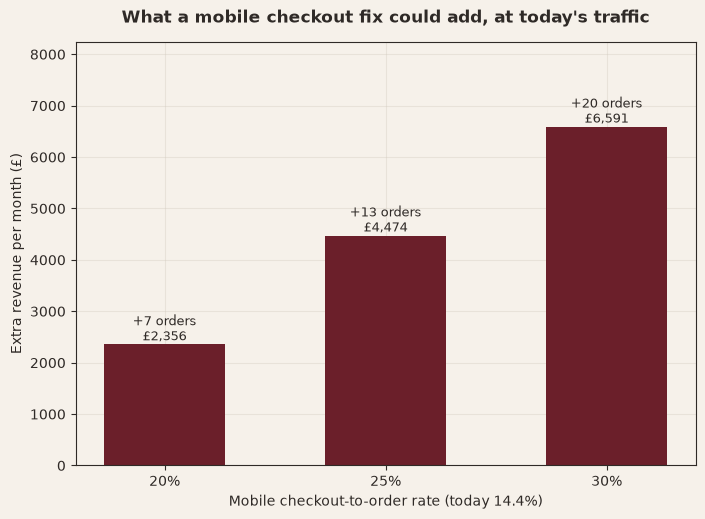

In [89]:
mob = analytics[analytics["device"] == "mobile"][["checkouts_started", "orders"]].sum()
n_months = analytics["month"].nunique()
print(n_months)
aov = analytics["revenue_gbp"].sum() / analytics["orders"].sum()
chk_pm = mob.checkouts_started / n_months
cur = mob.orders / mob.checkouts_started
targets = [t for t in (0.20, 0.25, 0.30) if t > cur]
rows = []
for t in targets:
    extra = chk_pm * (t - cur)
    rows.append({"target": f"{t:.0%}", "extra_orders_per_month": extra,
                 "extra_revenue_per_month": extra * aov,
                 "extra_gross_profit_per_month": extra * aov * MARGIN})
opp = pd.DataFrame(rows).set_index("target")

print(f"Mobile checkouts per month: {chk_pm:.0f} | current completion: {cur:.1} | average order value: £{aov:.0f}")
display(opp.round(0))

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(opp.index, opp.extra_revenue_per_month, color=OXBLOOD, width=0.55)
for b, (_, r) in zip(bars, opp.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, r.extra_revenue_per_month + 80,
            f"+{r.extra_orders_per_month:.0f} orders\n£{r.extra_revenue_per_month:,.0f}",
            ha="center", fontsize=9)
ax.set_ylim(0, opp.extra_revenue_per_month.max() * 1.25)
ax.set_xlabel(f"Mobile checkout-to-order rate (today {pct(cur)})")
ax.set_ylabel("Extra revenue per month (£)")
ax.set_title("What a mobile checkout fix could add, at today's traffic")
plt.show()